# Query-based: RT-DETR

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 81920 MiB


In [ ]:
import matplotlib.pyplot as plt, matplotlib.patches as patches

In [ ]:
import os
from pathlib import Path
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('kaggle')

if not Path('/content/data/train').exists():
    !kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p /content/data
    !cd /content/data && unzip -q '*.zip' && rm *.zip
else:
    print('Data is here')
ROOT = Path('/content/data')

100% 9.88G/9.88G [04:12<00:00, 42.0MB/s]



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PREP = Path('/content/prepared')
if not PREP.exists():
    !unzip -q /content/drive/MyDrive/УКУ/AI/hw2_prepared.zip -d /content
for split in ['train', 'val']:
    n = sum(1 for _ in (PREP / split / 'images').rglob('*.jpg'))
    print(f'{split}: {n} кадрів')

Mounted at /content/drive
train: 4868 кадрів
val: 571 кадрів


## Setup

In [ ]:
import random, cv2, numpy as np, torch
import torchvision.transforms.functional as TF

CLASSES = ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']
SEED, DEVICE = 42, 'cuda'

## Evaluation
Predictions are made on the original val frames (every 5th frame, 571 frames, not masked). Metrics are computed with pycocotools (`maxDets=500`); detections inside ignored regions are not penalised thanks to `iscrowd=1` in the ground truth. The same evaluation is used for every model.

In [ ]:
import json, contextlib, io, pandas as pd
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

with contextlib.redirect_stdout(io.StringIO()):
    gt = COCO(str(ROOT / 'val/annotations_coco.json'))
imgs_va = pd.DataFrame(gt.dataset['images']).rename(columns={'id': 'image_id'})
val_sub = imgs_va.sort_values(['video', 'frame_id'])
val_sub = val_sub[val_sub.groupby('video').cumcount() % 5 == 0]       # той самий кожен 5-й кадр
print('val frames for evaluation:', len(val_sub))

@torch.no_grad()
def predict(model, df, split='val', bs=4):
    """Передбачення на оригінальних кадрах -> список у COCO-форматі (bbox = [x, y, w, h] у пікселях)."""
    model.eval(); out = []
    for i in range(0, len(df), bs):
        rows = df.iloc[i:i + bs]
        ims = [TF.to_tensor(cv2.cvtColor(cv2.imread(str(ROOT / split / f)), cv2.COLOR_BGR2RGB)).to(DEVICE)
               for f in rows.file_name]
        with torch.autocast('cuda', dtype=torch.float16):
            res = model(ims)
        for iid, r in zip(rows.image_id, res):
            b = r['boxes'].float().cpu().numpy(); b[:, 2:] -= b[:, :2]      # xyxy -> xywh
            for box, s, l in zip(b, r['scores'].float().cpu().numpy(), r['labels'].cpu().numpy()):
                out.append({'image_id': int(iid), 'category_id': int(l),   # мітки 1..8 = COCO category_id
                            'bbox': [round(float(v), 2) for v in box], 'score': float(s)})
    return out

def evaluate(preds, img_ids):
    """COCO mAP + AP по класах."""
    with contextlib.redirect_stdout(io.StringIO()):
        dt = gt.loadRes(preds)
        E = COCOeval(gt, dt, 'bbox')
        E.params.imgIds = list(img_ids); E.params.maxDets = [1, 100, 500]
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    res = {'mAP': s[0], 'AP50': s[1], 'AP75': s[2], 'AP_small': s[3], 'AP_medium': s[4], 'AP_large': s[5]}
    prec = E.eval['precision']                                           # [IoU, recall, class, area, maxDets]
    for k, c in enumerate(CLASSES):
        p = prec[:, :, k, 0, -1]
        res[f'AP_{c}'] = float(p[p > -1].mean()) if (p > -1).any() else float('nan')
    return res

val frames for evaluation: 571


In [ ]:
!pip -q install ultralytics

for query-based we chose the default augmentation settings, because DETR models learn poorly with limited augmentation

In [ ]:
import os, yaml
from ultralytics import RTDETR

EPOCHS, IMGSZ, BATCH = 6, 1024, 4            # lower BATCH or IMGSZ on out-of-memory
RUN_DIR, RUN_NAME = '/content/drive/MyDrive/hw2_runs', 'rtdetr_l_6ep'

# ---- data: PREP/{train,val}/images/**.jpg with YOLO labels in PREP/{train,val}/labels/**.txt ----
counts = {}
for split in ['train', 'val']:
    lbls = list((PREP / split / 'labels').rglob('*.txt'))
    assert lbls, f'No YOLO labels in {PREP / split / "labels"}: the prepared data is in another format'
    counts[split] = [sum(1 for line in open(p) if line.strip()) for p in lbls]
busiest = max(counts['train'] + counts['val'])
print(f'objects per frame: mean {np.mean(counts["train"]):.0f}, max {busiest}')

DATA_YAML = '/content/rtdetr_data.yaml'
yaml.safe_dump({'path': str(PREP), 'train': 'train/images', 'val': 'val/images',
                'names': dict(enumerate(CLASSES))}, open(DATA_YAML, 'w'))

# ---- queries: about 1.2x the busiest frame, rounded up to 100, kept within [300, 900] ----
NQ = int(min(900, max(300, 100 * np.ceil(1.2 * busiest / 100))))
print('decoder queries:', NQ)

def set_queries(trainer):
    """Queries come from encoder top-k, so the count can change without losing pretrained weights."""
    for m in (trainer.model, trainer.ema.ema):
        m.model[-1].num_queries = NQ

model = RTDETR('rtdetr-l.pt')                # COCO-pretrained; the class heads are re-initialised for 8 classes
model.add_callback('on_train_start', set_queries)

model.train(
    data=DATA_YAML, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
    nbs=16,                                  # accumulate gradients to an effective batch of 16
    optimizer='AdamW', lr0=1e-4, lrf=0.1, weight_decay=1e-4,
    warmup_epochs=1,                         # the default of 3 would be half of the run
    close_mosaic=2,                          # last 2 epochs without mosaic
    amp=True, seed=SEED, device=0, workers=os.cpu_count(),
    save_period=1,                           # one checkpoint per epoch for the mAP-over-training plot
    project=RUN_DIR, name=RUN_NAME, exist_ok=True, verbose=False,
)



objects per frame: mean 45, max 158
decoder queries: 300
rt-detr-l summary: 470 layers, 32,822,516 parameters, 32,822,516 gradients, 109.9 GFLOPs
Transferred 941/941 items from pretrained weights
6 epochs completed in 0.518 hours.


In [ ]:
hist = pd.read_csv(f'{RUN_DIR}/{RUN_NAME}/results.csv')
hist.columns = hist.columns.str.strip()
print(hist[['epoch', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']])

   epoch  metrics/mAP50(B)  metrics/mAP50-95(B)
0      1           0.09303              0.04486
1      2           0.16677              0.08763
2      3           0.37998              0.19768
3      4           0.43959              0.22736
4      5           0.44425              0.22642
5      6           0.43931              0.22749


In [ ]:
def predict_rtdetr(weights, df, split='val', imgsz=IMGSZ, bs=8):
    m, out = RTDETR(weights), []
    files = [str(ROOT / split / f) for f in df.file_name]
    for i in range(0, len(df), bs):
        res = m.predict(files[i:i + bs], imgsz=imgsz, conf=0.001, max_det=500, verbose=False)
        for iid, r in zip(df.image_id.iloc[i:i + bs], res):
            b = r.boxes.xyxy.cpu().numpy(); b[:, 2:] -= b[:, :2]            # xyxy -> xywh
            for box, s, l in zip(b, r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy()):
                out.append({'image_id': int(iid), 'category_id': int(l) + 1,  # 0..7 -> 1..8
                            'bbox': [round(float(v), 2) for v in box], 'score': float(s)})
    return out

W = f'{RUN_DIR}/{RUN_NAME}/weights'
res_rtdetr = evaluate(predict_rtdetr(f'{W}/best.pt', val_sub), val_sub.image_id)
# per-epoch curve with your metric: loop over f'{W}/epoch{k}.pt' for k in range(EPOCHS)

In [ ]:
display(pd.Series(res_rtdetr))

,0
mAP,0.209002
AP50,0.412744
AP75,0.182885
AP_small,0.095963
AP_medium,0.185841
AP_large,0.388437
AP_person,0.245517
AP_bicycle,0.159597
AP_car,0.407291
AP_van,0.239151


Experiment 1: learning rates. All parameter groups warm up from zero (Ultralytics’ default bias warm-up starts at 0.1, an SGD setting), and the backbone trains at 1e-5 while the encoder and decoder stay at 1e-4, as in the RT-DETR paper.

Experiment 2: denoising budget. Frames contain up to 180 objects, so the default budget of 100 denoising queries yields a single denoising group. Experiment 2 raises it to 500, on top of Experiment 1.

In [ ]:
from ultralytics import RTDETR
from ultralytics.models.rtdetr.train import RTDETRTrainer


class TunedRTDETRTrainer(RTDETRTrainer):
    """RT-DETR trainer with a separate learning rate for the CNN backbone (layers listed under `backbone:`)."""
    backbone_mult = 1.0

    def build_optimizer(self, model, name='auto', lr=0.001, momentum=0.9, decay=1e-5, iterations=1e5):
        opt = super().build_optimizer(model, name, lr, momentum, decay, iterations)
        assert isinstance(opt, torch.optim.AdamW), 'this trainer expects optimizer="AdamW"'
        n_bb = len(model.yaml['backbone'])                                # 10 layers = HGNetv2
        bb = {id(p) for layer in model.model[:n_bb] for p in layer.parameters()}
        groups = []
        for g in opt.param_groups:                                        # weight / bn / bias
            for part, mult in (('backbone', self.backbone_mult), ('transformer', 1.0)):
                params = [p for p in g['params'] if (id(p) in bb) == (part == 'backbone')]
                if params:
                    groups.append({'params': params, 'lr': g['lr'] * mult, 'weight_decay': g['weight_decay'],
                                   'param_group': g['param_group'], 'part': part})
        for g in groups:
            print(f"lr group {g['part']:11s} {g['param_group']:6s} tensors={len(g['params']):3d} lr={g['lr']:.1e}")
        return torch.optim.AdamW(groups, lr=lr, betas=(momentum, 0.999), weight_decay=0.0,
                                 fused=next(model.parameters()).is_cuda)


def train_rtdetr(name, backbone_mult=1.0, warmup_bias_lr=0.1, num_dn=100, **overrides):
    def set_denoising(trainer):
        for m in (trainer.model, trainer.ema.ema):
            m.model[-1].num_denoising = num_dn
        print('denoising budget:', trainer.model.model[-1].num_denoising)

    TunedRTDETRTrainer.backbone_mult = backbone_mult
    model = RTDETR('rtdetr-l.pt')
    model.add_callback('on_train_start', set_denoising)
    args = dict(
        data=DATA_YAML, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, nbs=16,
        optimizer='AdamW', lr0=1e-4, lrf=0.1, weight_decay=1e-4,
        warmup_epochs=1, warmup_bias_lr=warmup_bias_lr, close_mosaic=2,
        amp=True, seed=SEED, device=0, workers=os.cpu_count(), save_period=1,
        project=RUN_DIR, name=name, exist_ok=True, verbose=False)
    args.update(overrides)
    model.train(trainer=TunedRTDETRTrainer, **args)
    return f'{RUN_DIR}/{name}'


runs = {'baseline': f'{RUN_DIR}/rtdetr_l_6ep'}
runs['exp1_lr'] = train_rtdetr('rtdetr_exp1_lr', backbone_mult=0.1, warmup_bias_lr=0.0)
runs['exp2_lr_dn'] = train_rtdetr('rtdetr_exp2_lr_dn', backbone_mult=0.1, warmup_bias_lr=0.0, num_dn=500)

lr group backbone    weight tensors= 80 lr=1.0e-05
lr group transformer weight tensors=126 lr=1.0e-04
lr group backbone    bn     tensors= 80 lr=1.0e-05
lr group transformer bn     tensors= 63 lr=1.0e-04
lr group backbone    bias   tensors= 80 lr=1.0e-05
lr group transformer bias   tensors=146 lr=1.0e-04
denoising budget: 100
6 epochs completed in 0.523 hours.
denoising budget: 500
6 epochs completed in 0.530 hours.


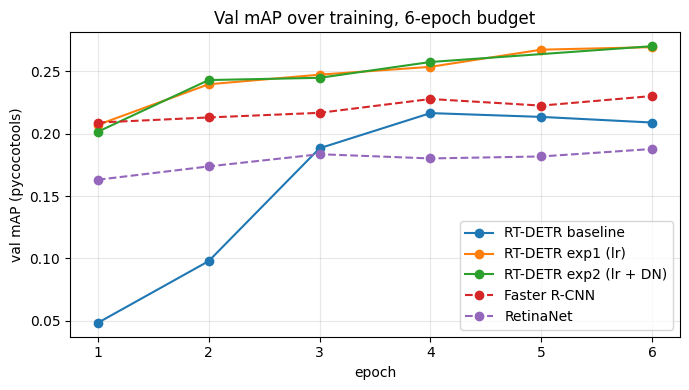

,RT-DETR baseline,RT-DETR exp1 (lr),RT-DETR exp2 (lr + DN),Faster R-CNN,RetinaNet
1,0.0482,0.2071,0.2016,0.2090,0.1631
2,0.0978,0.2397,0.2431,0.2131,0.1738
3,0.1884,0.2474,0.2449,0.2168,0.1836
4,0.2166,0.2537,0.2576,0.2279,0.1802
5,0.2135,0.2675,NaN,0.2226,0.1818
6,0.2090,0.2695,0.2703,0.2303,0.1878


In [ ]:
import glob, re

def curve(run_dir):
    """(epoch, val mAP) for every saved checkpoint; last.pt = final epoch."""
    pts = []
    for p in glob.glob(f'{run_dir}/weights/epoch*.pt'):
        ep = int(re.findall(r'epoch(\d+)', p)[-1]) + 1                     # epoch0.pt -> epoch 1
        pts.append((ep, p))
    if EPOCHS not in [e for e, _ in pts]:
        pts.append((EPOCHS, f'{run_dir}/weights/last.pt'))
    pts.sort()
    return [e for e, _ in pts], [evaluate(predict_rtdetr(p, val_sub), val_sub.image_id)['mAP'] for _, p in pts]

ep6 = list(range(1, EPOCHS + 1))

# exp2: epoch4.pt / epoch5.pt were lost when Drive ran out of space, and its last.pt holds the epoch-3 weights.
# Epoch 6 (epoch5.pt) was scored with the same evaluate before it was lost: 0.2703 (pipeline notebook).
exp2_curve = ([1, 2, 3, 4, 6], [0.2016, 0.2431, 0.2449, 0.2576, 0.2703])

curves = {'RT-DETR baseline':       curve(f'{RUN_DIR}/rtdetr_l_6ep'),
          'RT-DETR exp1 (lr)':      curve(f'{RUN_DIR}/rtdetr_exp1_lr'),
          'RT-DETR exp2 (lr + DN)': exp2_curve,
          'Faster R-CNN':           (ep6, [0.2090, 0.2131, 0.2168, 0.2279, 0.2226, 0.2303]),
          'RetinaNet':              (ep6, [0.1631, 0.1738, 0.1836, 0.1802, 0.1818, 0.1878])}

fig, ax = plt.subplots(figsize=(7, 4))
for label, (x, y) in curves.items():
    ax.plot(x, y, marker='o', ls='--' if label in ('Faster R-CNN', 'RetinaNet') else '-', label=label)
ax.set_xlabel('epoch'); ax.set_ylabel('val mAP (pycocotools)')
ax.set_title('Val mAP over training, 6-epoch budget'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig('rtdetr_vs_cnn_curve.png', dpi=120); plt.show()

pd.DataFrame({k: pd.Series(y, index=x) for k, (x, y) in curves.items()}).round(4)

Results. The learning-rate recipe raised mAP from 0.209 to 0.270; the larger denoising budget added nothing (0.2695 vs 0.2703). Faster R-CNN plateaus after the first epoch, while tuned RT-DETR starts at the same level and keeps improving. RT-DETR has not converged within 6 epochs: exp1 still improves at the last epoch (0.2675 -> 0.2695). The untuned run peaks at epoch 4 (0.217) and then drops to 0.209. The exp2 checkpoints for epochs 5–6 were lost when Google Drive ran out of space; its epoch-6 value was scored earlier with the same evaluate.